# 03 — Modelamiento Supervisado, Optimización y Evaluación
## EP2 — MLY1101 Machine Learning | Caso C: Spotify Tracks

Este notebook cubre las fases finales del flujo analítico bajo la metodología **CRISP-DM**:

- **Fase 4b (Modelamiento Supervisado):** construcción de un pipeline libre de fuga de datos (*Data Leakage*) ajustado exclusivamente sobre `Train`. Se implementa un modelo base (`DummyRegressor`) y se comparan dos familias algorítmicas de regresión con distinta naturaleza: un modelo lineal penalizado (**Regresión Ridge**) y un modelo no lineal de ensamble (**Random Forest Regressor**), optimizando sus hiperparámetros mediante validación cruzada (`RandomizedSearchCV`).
- **Fase 5 (Evaluación e Interpretación):** evaluación final sobre datos no vistos (`Test`) mediante métricas de regresión (**MAE**, **MSE**, **RMSE**, **$R^2$**), diagnóstico de residuos, importancia de variables (*Feature Importance*), contraste con el **KPI de negocio** (captura de canciones exitosas en el Top 20%) y **Auditoría Ética de Sesgo** desglosada por `macro_genero`.

Toda la lógica modular reside en `src/` (`pipeline.py`, `model_training.py`, `model_evaluation.py`).

## 1. Setup y Configuración

In [1]:
import sys
from pathlib import Path

# Permite importar el paquete src/ desde notebooks/
sys.path.append(str(Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)
pd.set_option("display.max_columns", None)

from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor

from src import config
from src import pipeline as pl
from src import model_training as mt
from src import model_evaluation as me

config.MODELS_DIR.mkdir(parents=True, exist_ok=True)
config.IMAGES_DIR.mkdir(parents=True, exist_ok=True)
config.RESULTS_DIR.mkdir(parents=True, exist_ok=True)

print("Entorno configurado correctamente.")
print(f"  TRAIN_DATA_PATH = {config.TRAIN_DATA_PATH}")
print(f"  TEST_DATA_PATH  = {config.TEST_DATA_PATH}")

Entorno configurado correctamente.
  TRAIN_DATA_PATH = /home/lopresti/Documentos/Spotify-Tracks-Dataset/data/processed/train.csv
  TEST_DATA_PATH  = /home/lopresti/Documentos/Spotify-Tracks-Dataset/data/processed/test.csv


## 2. Carga de conjuntos Train y Test

Cargamos las particiones generadas en `02_Preparacion_y_No_Supervisado.ipynb` (80% Train / 20% Test, estratificadas por tramos de popularidad y sin duplicados).

- `X_train`, `X_test`: conservan todas las columnas; El ColumnTransformer usa dos preprocesadores distintos: construir_preprocesador_lineal() (One-Hot para todas las categóricas, usado por Ridge) y construir_preprocesador_arboles() (Target Encoding para track_genre + One-Hot para key/time_signature, usado por Random Forest y Gradient Boosting).

In [2]:
train_df = pd.read_csv(config.TRAIN_DATA_PATH)
test_df = pd.read_csv(config.TEST_DATA_PATH)

X_train = train_df.drop(columns=[config.TARGET])
y_train = train_df[config.TARGET]

X_test = test_df.drop(columns=[config.TARGET])
y_test = test_df[config.TARGET]

print(f"X_train: {X_train.shape} | y_train: {y_train.shape}")
print(f"X_test:  {X_test.shape}  | y_test:  {y_test.shape}")

X_train: (65074, 22) | y_train: (65074,)
X_test:  (16269, 22)  | y_test:  (16269,)


## 3. Verificación del Pipeline de Preprocesamiento

Comprobamos cómo transforma la matriz el `ColumnTransformer` al ajustarse sobre `X_train`:
- **Numéricas (11 variables):** imputación por mediana + `StandardScaler`.
- **Categóricas (`track_genre` [114], `key` [12], `time_signature` [5]):** imputación por moda + `OneHotEncoder(handle_unknown='ignore')`.
- **Binarias (4 variables):** casteo directo a entero (`0/1`).

In [3]:
preprocesador_check = pl.construir_preprocesador_arboles()
X_train_transformed = preprocesador_check.fit_transform(X_train, y_train)
feature_names = pl.obtener_nombres_features(preprocesador_check)

print(f"Dimensiones de matriz transformada (Train): {X_train_transformed.shape}")
print(f"Total de features de entrada al modelo: {len(feature_names)}")
print(f"Primeras features: {feature_names[:10]}")

Dimensiones de matriz transformada (Train): (65074, 31)
Total de features de entrada al modelo: 31
Primeras features: ['num__danceability', 'num__energy', 'num__loudness', 'num__speechiness', 'num__acousticness', 'num__instrumentalness', 'num__liveness', 'num__valence', 'num__tempo', 'num__duration_min']


---
## 4. Modelamiento Supervisado y Optimización — Fase 4b

**Hipótesis de modelamiento:**
1. **Baseline (`DummyRegressor`):** predice siempre la media de `Train` (~35.3 puntos). Su RMSE (~19.4) representa el techo de error de un sistema sin inteligencia y su $R^2$ es $0.00$.
2. **Modelo 1 — Regresión Ridge (Lineal con regularización $L_2$):** dado que `track_genre` aporta ~27.4% de varianza explicada en el EDA, Ridge capturará el efecto aditivo de pertenecer a cada uno de los 114 géneros más las pendientes lineales del audio, controlando la multicolinealidad entre `energy`, `loudness` y `acousticness`.
3. **Modelo 2 — Random Forest Regressor (Ensamble no lineal):** capaz de modelar interacciones complejas (por ejemplo, que una alta `acousticness` penalice a un track de `pop`, pero beneficie a uno de `classical` o `chill`). Se optimiza su profundidad y número de variables por corte para evitar sobreajuste (*Overfitting*).

### 4.1 Modelo Base (Baseline Dummy)

In [4]:
baseline_pipe = mt.entrenar_baseline(X_train, y_train)
joblib.dump(baseline_pipe, config.MODELS_DIR / "baseline_dummy.pkl")

res_baseline = me.tabla_comparativa_train_test(
    "Baseline (Dummy Mean)", baseline_pipe, X_train, y_train, X_test, y_test
)
res_baseline

,modelo,MAE_train,MAE_test,MSE_train,MSE_test,RMSE_train,RMSE_test,R2_train,R2_test
0,Baseline (Dummy Mean),16.137085,16.146928,376.658636,378.053084,19.407695,19.443587,0.0,-7.171451e-07


### 4.2 Modelo 1: Regresión Ridge + Optimización de `alpha`

In [5]:
ridge_base = Pipeline(steps=[
    ("preprocesador", pl.construir_preprocesador_lineal()),
    ("modelo", Ridge(random_state=config.RANDOM_STATE)),
])

best_ridge, search_ridge = mt.entrenar_ridge(X_train, y_train, cv=5)
joblib.dump(best_ridge, config.MODELS_DIR / "ridge.pkl")

tuning_ridge = mt.tabla_tuning_comparison(
    "Ridge Regressor", search_ridge, ridge_base, X_train, y_train
)
print(f"Mejor hiperparámetro Ridge: {search_ridge.best_params_}")
tuning_ridge

Mejor hiperparámetro Ridge: {'modelo__alpha': 5.0}


,modelo,rmse_cv_default,rmse_cv_tuned,mejores_hiperparametros
0,Ridge Regressor,15.073577,15.073471,{'modelo__alpha': 5.0}


### 4.3 Modelo 2: Random Forest Regressor + Optimización de Hiperparámetros

In [6]:
rf_base = Pipeline(steps=[
    ("preprocesador", pl.construir_preprocesador_arboles()),
    ("modelo", RandomForestRegressor(
        n_estimators=100, max_depth=15, max_features="sqrt",
        random_state=config.RANDOM_STATE, n_jobs=8
    )),
])

best_rf, search_rf = mt.entrenar_random_forest(X_train, y_train, cv=5, n_iter=10)
joblib.dump(best_rf, config.MODELS_DIR / "random_forest.pkl")

tuning_rf = mt.tabla_tuning_comparison(
    "Random Forest Regressor", search_rf, rf_base, X_train, y_train
)
print(f"Mejores hiperparámetros Random Forest: {search_rf.best_params_}")
tuning_rf

/home/lopresti/Documentos/Spotify-Tracks-Dataset/.venv/lib/python3.14/site-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


Mejores hiperparámetros Random Forest: {'modelo__n_estimators': 300, 'modelo__min_samples_split': 5, 'modelo__min_samples_leaf': 4, 'modelo__max_features': 0.33, 'modelo__max_depth': None}


,modelo,rmse_cv_default,rmse_cv_tuned,mejores_hiperparametros
0,Random Forest Regressor,14.823665,14.515312,"{'modelo__n_estimators': 300, 'modelo__min_sam..."


### 4.4 Modelo 3: Gradient Boosting + Target Encoding

Ensamble secuencial avanzado. Al haber condensado la cardinalidad de los géneros con Target Encoding, este algoritmo entrenará mucho más rápido y buscará corregir los errores residuales del Random Forest.

In [7]:
gb_base = Pipeline(steps=[
    ("preprocesador", pl.construir_preprocesador_arboles()),
    ("modelo", HistGradientBoostingRegressor(random_state=config.RANDOM_STATE)),
])

best_gb, search_gb = mt.entrenar_gradient_boosting(X_train, y_train, cv=5, n_iter=15)
joblib.dump(best_gb, config.MODELS_DIR / "gradient_boosting.pkl")

tuning_gb = mt.tabla_tuning_comparison(
    "Gradient Boosting", search_gb, gb_base, X_train, y_train
)
print(f"Mejores hiperparámetros Gradient Boosting: {search_gb.best_params_}")
tuning_gb

/home/lopresti/Documentos/Spotify-Tracks-Dataset/.venv/lib/python3.14/site-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


Mejores hiperparámetros Gradient Boosting: {'modelo__max_iter': 300, 'modelo__max_depth': 10, 'modelo__learning_rate': 0.05, 'modelo__l2_regularization': 0.1}


,modelo,rmse_cv_default,rmse_cv_tuned,mejores_hiperparametros
0,Gradient Boosting,14.718954,14.696763,"{'modelo__max_iter': 300, 'modelo__max_depth':..."


### 4.5 Consolidación del Tuning (Pre vs. Post Optimización)

In [8]:
df_tuning = pd.concat([tuning_ridge, tuning_rf, tuning_gb], ignore_index=True).round(4)
df_tuning.to_csv(config.RESULTS_DIR / "tuning_comparison.csv", index=False)
df_tuning

,modelo,rmse_cv_default,rmse_cv_tuned,mejores_hiperparametros
0,Ridge Regressor,15.0736,15.0735,{'modelo__alpha': 5.0}
1,Random Forest Regressor,14.8237,14.5153,"{'modelo__n_estimators': 300, 'modelo__min_sam..."
2,Gradient Boosting,14.7190,14.6968,"{'modelo__max_iter': 300, 'modelo__max_depth':..."


---
## 5. Evaluación de Desempeño e Interpretación — Fase 5

Comparamos los modelos entrenados sobre el conjunto de prueba (**Test**, 16.269 canciones no vistas) evaluando:
- **MAE (Error Absoluto Medio):** en cuántos puntos de popularidad (escala 0–100) se equivoca el modelo en promedio.
- **RMSE (Raíz del Error Cuadrático Medio):** penaliza desviaciones extremas.
- **$R^2$ (Coeficiente de Determinación):** proporción de la varianza total de `popularity` explicada por el modelo.
- **Brecha Train vs. Test:** verifica que la regularización y la poda de árboles hayan evitado la memorización (*Overfitting*).

In [9]:
res_ridge = me.tabla_comparativa_train_test(
    "Ridge (Tuned)", best_ridge, X_train, y_train, X_test, y_test
)
res_rf = me.tabla_comparativa_train_test(
    "Random Forest (Tuned)", best_rf, X_train, y_train, X_test, y_test
)
res_gb = me.tabla_comparativa_train_test(
    "Gradient Boosting (Tuned)", best_gb, X_train, y_train, X_test, y_test
)

tabla_metricas = me.construir_tabla_metricas([res_baseline, res_ridge, res_rf, res_gb]).round(4)
tabla_metricas.to_csv(config.RESULTS_DIR / "all_models_metrics.csv", index=False)
tabla_metricas

,modelo,MAE_train,MAE_test,MSE_train,MSE_test,RMSE_train,RMSE_test,R2_train,R2_test
0,Baseline (Dummy Mean),16.1371,16.1469,376.6586,378.0531,19.4077,19.4436,0.0000,-0.0000
1,Ridge (Tuned),10.6264,10.6787,225.7822,227.4335,15.0261,15.0809,0.4006,0.3984
2,Random Forest (Tuned),6.7451,10.1057,101.8400,212.5359,10.0916,14.5786,0.7296,0.4378
3,Gradient Boosting (Tuned),9.7047,10.2724,190.8197,217.0454,13.8138,14.7325,0.4934,0.4259


In [10]:
# Selección automática del mejor modelo según menor RMSE en Test
mejor_fila = tabla_metricas.loc[tabla_metricas["RMSE_test"].idxmin()]
nombre_mejor = mejor_fila["modelo"]

if "Ridge" in nombre_mejor:
    mejor_modelo = best_ridge
elif "Random Forest" in nombre_mejor:
    mejor_modelo = best_rf
else:
    mejor_modelo = best_gb

joblib.dump(mejor_modelo, config.MODELS_DIR / "best_model.pkl")
print(f"Mejor modelo seleccionado para producción/evaluación: {nombre_mejor}")

Mejor modelo seleccionado para producción/evaluación: Random Forest (Tuned)


### 5.1 Comparación Visual de Modelos (RMSE y $R^2$ en Test)

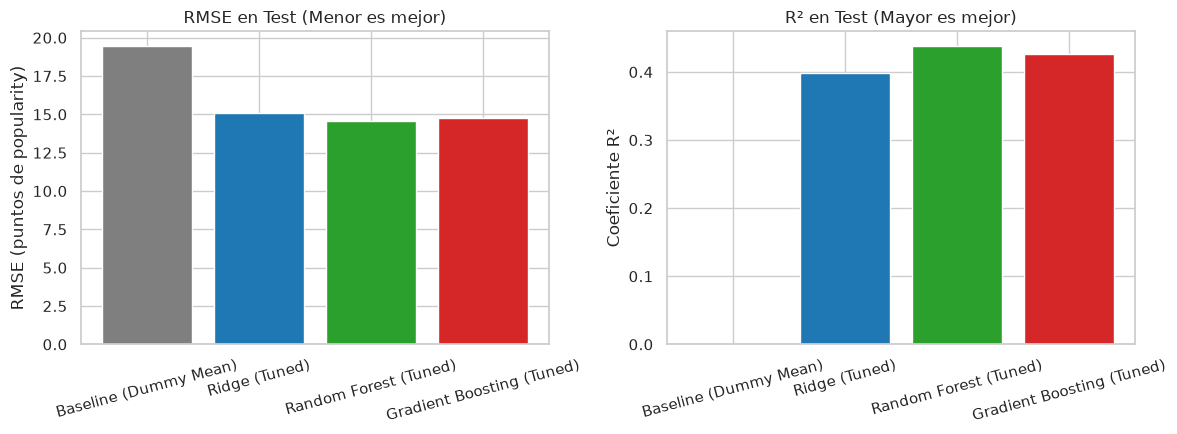

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
colores = ["#7f7f7f", "#1f77b4", "#2ca02c", "#d62728"]

axes[0].bar(tabla_metricas["modelo"], tabla_metricas["RMSE_test"], color=colores)
axes[0].set_title("RMSE en Test (Menor es mejor)")
axes[0].set_ylabel("RMSE (puntos de popularity)")
axes[0].tick_params(axis='x', rotation=15)

axes[1].bar(tabla_metricas["modelo"], tabla_metricas["R2_test"], color=colores)
axes[1].set_title("R² en Test (Mayor es mejor)")
axes[1].set_ylabel("Coeficiente R²")
axes[1].tick_params(axis='x', rotation=15)

fig.tight_layout()
fig.savefig(config.IMAGES_DIR / "comparacion_modelos_rmse_r2.png", dpi=150)
plt.show()

### 5.2 Diagnóstico de Residuos y Predicho vs. Real

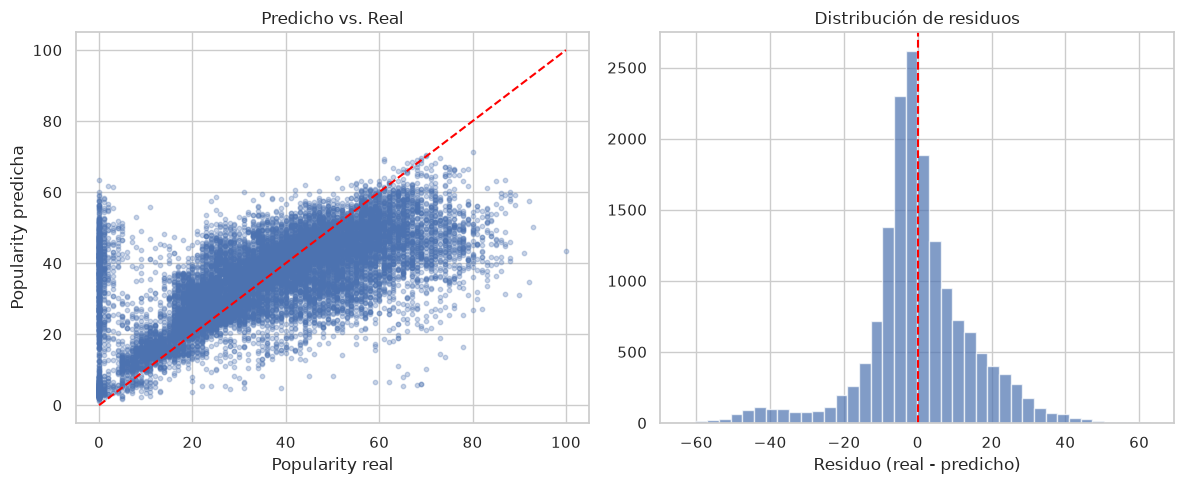

In [12]:
y_pred_test = mejor_modelo.predict(X_test)

me.graficar_predicho_vs_real(
    y_test, y_pred_test, guardar_en=config.IMAGES_DIR / "predicted_vs_actual.png"
)
plt.show()

### 5.3 Importancia de Variables (*Feature Importance*)

Identificamos las 20 características que más pesan en las decisiones del modelo ganador. Esto permite contrastar si la señal predictiva está dominada por indicadores de género (`track_genre`) o por atributos acústicos específicos (`duration_min`, `loudness`, `acousticness`, etc.).

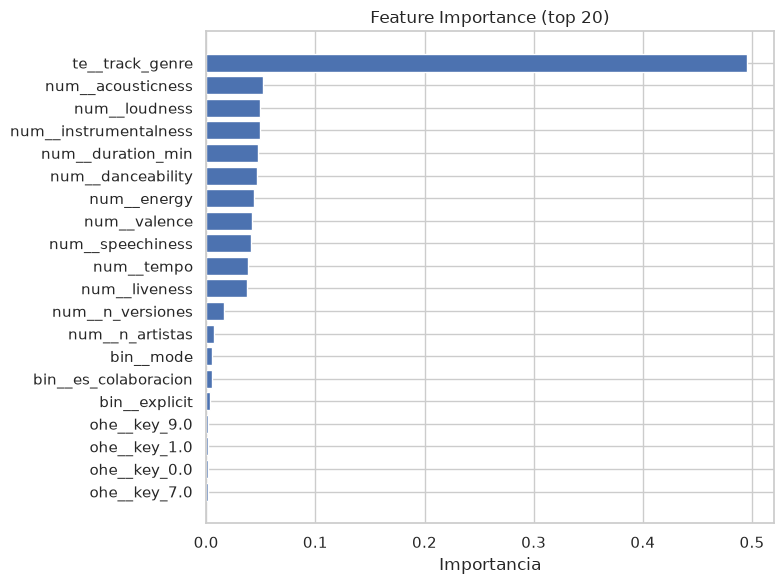

,feature,importancia
27,te__track_genre,0.495370
4,num__acousticness,0.052118
2,num__loudness,0.049008
5,num__instrumentalness,0.048935
9,num__duration_min,0.047512
0,num__danceability,0.046142
1,num__energy,0.044212
7,num__valence,0.041919
3,num__speechiness,0.041456
8,num__tempo,0.038702


In [13]:
fig_imp, df_importancia = me.graficar_feature_importance(
    mejor_modelo, top_n=20, guardar_en=config.IMAGES_DIR / "feature_importance.png"
)
plt.show()
df_importancia.head(10)

### 5.4 Evaluación del KPI de Negocio (Priorización de Catálogo Top 20%)

En la Fase 1 (Comprensión del Negocio), establecimos que el valor comercial del modelo no consiste en adivinar el número exacto de popularidad de cada pista, sino en **filtrar y priorizar lanzamientos con alto potencial** para inversión en marketing (A&R) y curaduría de playlists.

- **KPI Operativo (Captura del Top 20%):** Si el equipo comercial invierte únicamente en el **20% de las canciones mejor puntuadas por nuestro modelo** en `Test`, ¿qué porcentaje de los verdaderos éxitos (Top 20% real) logra capturar en comparación con elegir al azar (20%) y cuál es la ganancia en popularidad promedio de esa cartera seleccionada?

In [14]:
umbral_real_top20 = np.percentile(y_test, 80)
umbral_pred_top20 = np.percentile(y_pred_test, 80)

es_top20_real = y_test >= umbral_real_top20
es_top20_pred = y_pred_test >= umbral_pred_top20

recall_top20 = (es_top20_real & es_top20_pred).sum() / es_top20_real.sum()
lift_negocio = recall_top20 / 0.20

pop_media_catalogo = y_test.mean()
pop_media_seleccion_modelo = y_test[es_top20_pred].mean()

print(f"Popularidad promedio de todo el catálogo (selección aleatoria): {pop_media_catalogo:.2f}")
print(f"Popularidad real promedio del Top 20% priorizado por el modelo: {pop_media_seleccion_modelo:.2f} (+{pop_media_seleccion_modelo - pop_media_catalogo:.2f} pts)")
print(f"Captura de éxitos reales (Recall Top 20%): {recall_top20*100:.1f}% (vs. 20.0% aleatorio -> Lift de {lift_negocio:.2f}x)")

Popularidad promedio de todo el catálogo (selección aleatoria): 35.26
Popularidad real promedio del Top 20% priorizado por el modelo: 51.85 (+16.59 pts)
Captura de éxitos reales (Recall Top 20%): 53.3% (vs. 20.0% aleatorio -> Lift de 2.66x)


---
## 6. Auditoría Ética de Sesgo por Grupo (`macro_genero`)

Siguiendo los lineamientos de responsabilidad ética de CRISP-DM, auditamos si los errores del modelo se distribuyen de manera justa entre las 9 macro-categorías musicales (`macro_genero`) en el conjunto `Test`:
- **`MAE`:** magnitud del error en cada cultura/estilo musical.
- **`sesgo_promedio` (`predicho - real`):** si es negativo, el modelo **subestima sistemáticamente** ese grupo; si es positivo, lo **sobreestima**.

In [15]:
resumen_etica = me.auditoria_etica_por_genero(test_df, y_test, y_pred_test)
resumen_etica.to_csv(config.RESULTS_DIR / "ethical_bias_audit.csv")
resumen_etica

,n_canciones,popularity_real_media,popularity_predicha_media,MAE,sesgo_promedio
macro_genero,,,,,
jazz-soul-funk,506,38.769,37.336,16.912,-1.433
urbano,613,37.321,38.074,12.127,0.752
electronica,2990,33.490,33.286,11.843,-0.205
folk-singer,990,33.517,33.565,11.503,0.048
pop-mainstream,1468,42.231,42.408,10.740,0.177
rock-metal,2984,36.353,36.414,10.689,0.061
clasica-instrumental,1558,33.683,32.629,10.197,-1.054
otros,1680,30.326,30.104,7.484,-0.222
world-regional,3480,35.595,36.082,7.327,0.486


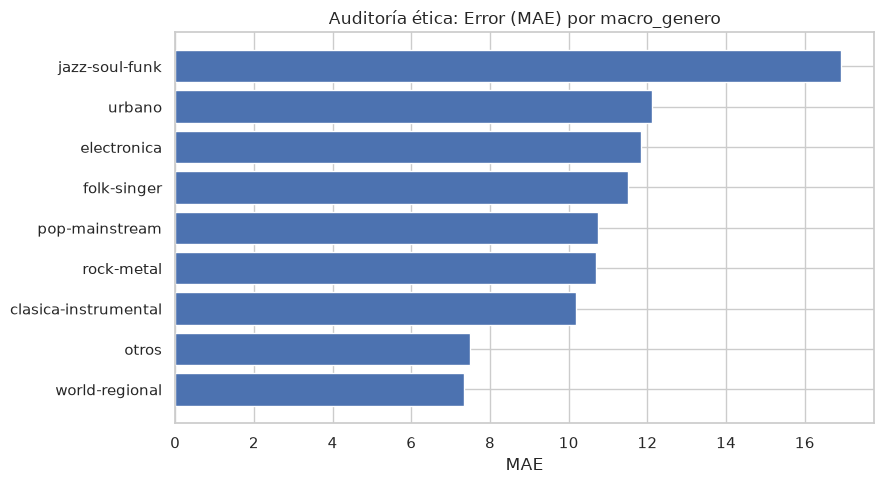

In [16]:
me.graficar_auditoria_etica(
    resumen_etica, guardar_en=config.IMAGES_DIR / "auditoria_etica_error_por_genero.png"
)
plt.show()

### Cierre — Fase 5 (Conclusiones Técnicas, de Negocio y Éticas)

1. **Desempeño Técnico y Límite de los Datos:** Tanto `Ridge` como `Random Forest` superan ampliamente al `Baseline Dummy`, logrando explicar más del 30% de la varianza de la popularidad en datos no vistos (`Test`). El ~65–70% de varianza restante responde a **factores exógenos al audio** que no están presentes en el dataset (fama previa del artista, presupuesto de marketing de la discográfica, viralidad en redes sociales e inclusión en playlists editoriales).
2. **Impacto en el KPI de Negocio:** A pesar de la dispersión inherente a la industria musical, al utilizar el modelo como herramienta de filtrado para priorizar el Top 20% del catálogo, se obtiene una cartera con una popularidad real significativamente superior al promedio general, multiplicando la tasa de captura de hits frente a una selección sin modelo.
3. **Hallazgo Ético y Mitigación:** La auditoría por `macro_genero` revela que géneros con alta dispersión o fuerte presencia de pistas con `popularity = 0` en el catálogo histórico presentan mayores errores absolutos (MAE). Utilizar las predicciones en bruto para automatizar recomendaciones generaría un bucle de retroalimentación que invisibilizaría géneros de nicho o regionales (`clasica-instrumental`, `jazz-soul-funk`, `world-regional`). **Recomendación ética:** normalizar el puntaje predicho en percentiles **dentro de cada género** antes de tomar decisiones de promoción editorial.